# EDA – Datenbereinigung (einfache Version)
**King County House Sales** · Rohdaten: `data/eda_tk.csv` → bereinigt: `data/eda_tk_cleaned.csv`

| # | Schritt |
|---|---|
| 1 | Daten laden |
| 2 | Erster Überblick |
| 3 | Duplikate |
| 4 | Fehlende Werte analysieren |
| 5 | Fehlende Werte auffüllen |
| 6 | Datenfehler korrigieren |
| 7 | sqft → qm umrechnen |
| 8 | Keller: Wie viel zählt er zur Wohnfläche? |
| 9 | Preis pro qm |
| 10 | Abschlusscheck & Export |

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1 · Daten laden

In [ ]:
# Das Datum wird direkt beim Einlesen in datetime umgewandelt
df = pd.read_csv("data/eda_tk.csv", parse_dates=["date"])
df.shape

(21597, 22)

## 2 · Erster Überblick

In [ ]:
display(df.head())
df.info()
df.describe()

,sale_id,house_id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,1,7129300520,2014-10-13,"221,900.00",3.00,1.00,"1,180.00","5,650.00",1.00,NaN,...,7,"1,180.00",0.00,1955,0.00,98178,47.51,-122.26,"1,340.00","5,650.00"
1,2,6414100192,2014-12-09,"538,000.00",3.00,2.25,"2,570.00","7,242.00",2.00,0.00,...,7,"2,170.00",400.00,1951,"19,910.00",98125,47.72,-122.32,"1,690.00","7,639.00"
2,3,5631500400,2015-02-25,"180,000.00",2.00,1.00,770.00,"10,000.00",1.00,0.00,...,6,770.00,0.00,1933,NaN,98028,47.74,-122.23,"2,720.00","8,062.00"
3,4,2487200875,2014-12-09,"604,000.00",4.00,3.00,"1,960.00","5,000.00",1.00,0.00,...,7,"1,050.00",910.00,1965,0.00,98136,47.52,-122.39,"1,360.00","5,000.00"
4,5,1954400510,2015-02-18,"510,000.00",3.00,2.00,"1,680.00","8,080.00",1.00,0.00,...,8,"1,680.00",0.00,1987,0.00,98074,47.62,-122.05,"1,800.00","7,503.00"


<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21597 non-null  int64         
 1   house_id       21597 non-null  int64         
 2   date           21597 non-null  datetime64[us]
 3   price          21597 non-null  float64       
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

,sale_id,house_id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,"21,597.00","21,597.00",21597,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","19,206.00",...,"21,597.00","21,597.00","21,145.00","21,597.00","17,749.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,"10,799.00","4,580,474,287.77",2014-10-29 04:20:38.171968,"540,296.57",3.37,2.12,"2,080.32","15,099.41",1.49,0.01,...,7.66,"1,788.60",291.86,"1,971.00",836.65,"98,077.95",47.56,-122.21,"1,986.62","12,758.28"
min,1.00,"1,000,102.00",2014-05-02 00:00:00,"78,000.00",1.00,0.50,370.00,520.00,1.00,0.00,...,3.00,370.00,0.00,"1,900.00",0.00,"98,001.00",47.16,-122.52,399.00,651.00
25%,"5,400.00","2,123,049,175.00",2014-07-22 00:00:00,"322,000.00",3.00,1.75,"1,430.00","5,040.00",1.00,0.00,...,7.00,"1,190.00",0.00,"1,951.00",0.00,"98,033.00",47.47,-122.33,"1,490.00","5,100.00"
50%,"10,799.00","3,904,930,410.00",2014-10-16 00:00:00,"450,000.00",3.00,2.25,"1,910.00","7,618.00",1.50,0.00,...,7.00,"1,560.00",0.00,"1,975.00",0.00,"98,065.00",47.57,-122.23,"1,840.00","7,620.00"
75%,"16,198.00","7,308,900,490.00",2015-02-17 00:00:00,"645,000.00",4.00,2.50,"2,550.00","10,685.00",2.00,0.00,...,8.00,"2,210.00",560.00,"1,997.00",0.00,"98,118.00",47.68,-122.12,"2,360.00","10,083.00"
max,"21,597.00","9,900,000,190.00",2015-05-27 00:00:00,"7,700,000.00",33.00,8.00,"13,540.00","1,651,359.00",3.50,1.00,...,13.00,"9,410.00","4,820.00","2,015.00","20,150.00","98,199.00",47.78,-121.31,"6,210.00","871,200.00"
std,"6,234.66","2,876,735,715.75",NaN,"367,368.14",0.93,0.77,918.11,"41,412.64",0.54,0.09,...,1.17,827.76,442.49,29.38,"4,000.11",53.51,0.14,0.14,685.23,"27,274.44"


**Was fällt auf?**
* `bedrooms` hat einen Maximalwert von **33**, das ist verdächtig.
* `yr_renovated` hat Werte bis ca. **20.150**, das ist kein gültiges Jahr.
* `waterfront`, `view`, `sqft_basement` und `yr_renovated` haben fehlende Werte.

## 3 · Duplikate
`sale_id` ist in jeder Zeile anders. Deshalb lassen wir die Spalte beim Vergleich weg, sonst findet `duplicated()` nie etwas.
Wenn dasselbe Haus am selben Tag zweimal vorkommt, wurde der Verkauf doppelt erfasst.

In [ ]:
print("Doppelte Zeilen (ohne sale_id):", df.drop(columns="sale_id").duplicated().sum())
print("Gleiches Haus am gleichen Tag: ", df.duplicated(subset=["house_id", "date"]).sum())

df = df.drop_duplicates(subset=["house_id", "date"]).reset_index(drop=True)

# Gleiches Haus an einem anderen Tag = Weiterverkauf, also eine echte eigene Transaktion -> bleibt drin
print("Weiterverkäufe:                ", df["house_id"].duplicated().sum())

Doppelte Zeilen (ohne sale_id): 0
Gleiches Haus am gleichen Tag:  0
Weiterverkäufe:                 177


## 4 · Fehlende Werte analysieren

waterfront       2391
view               63
sqft_basement     452
yr_renovated     3848
dtype: int64

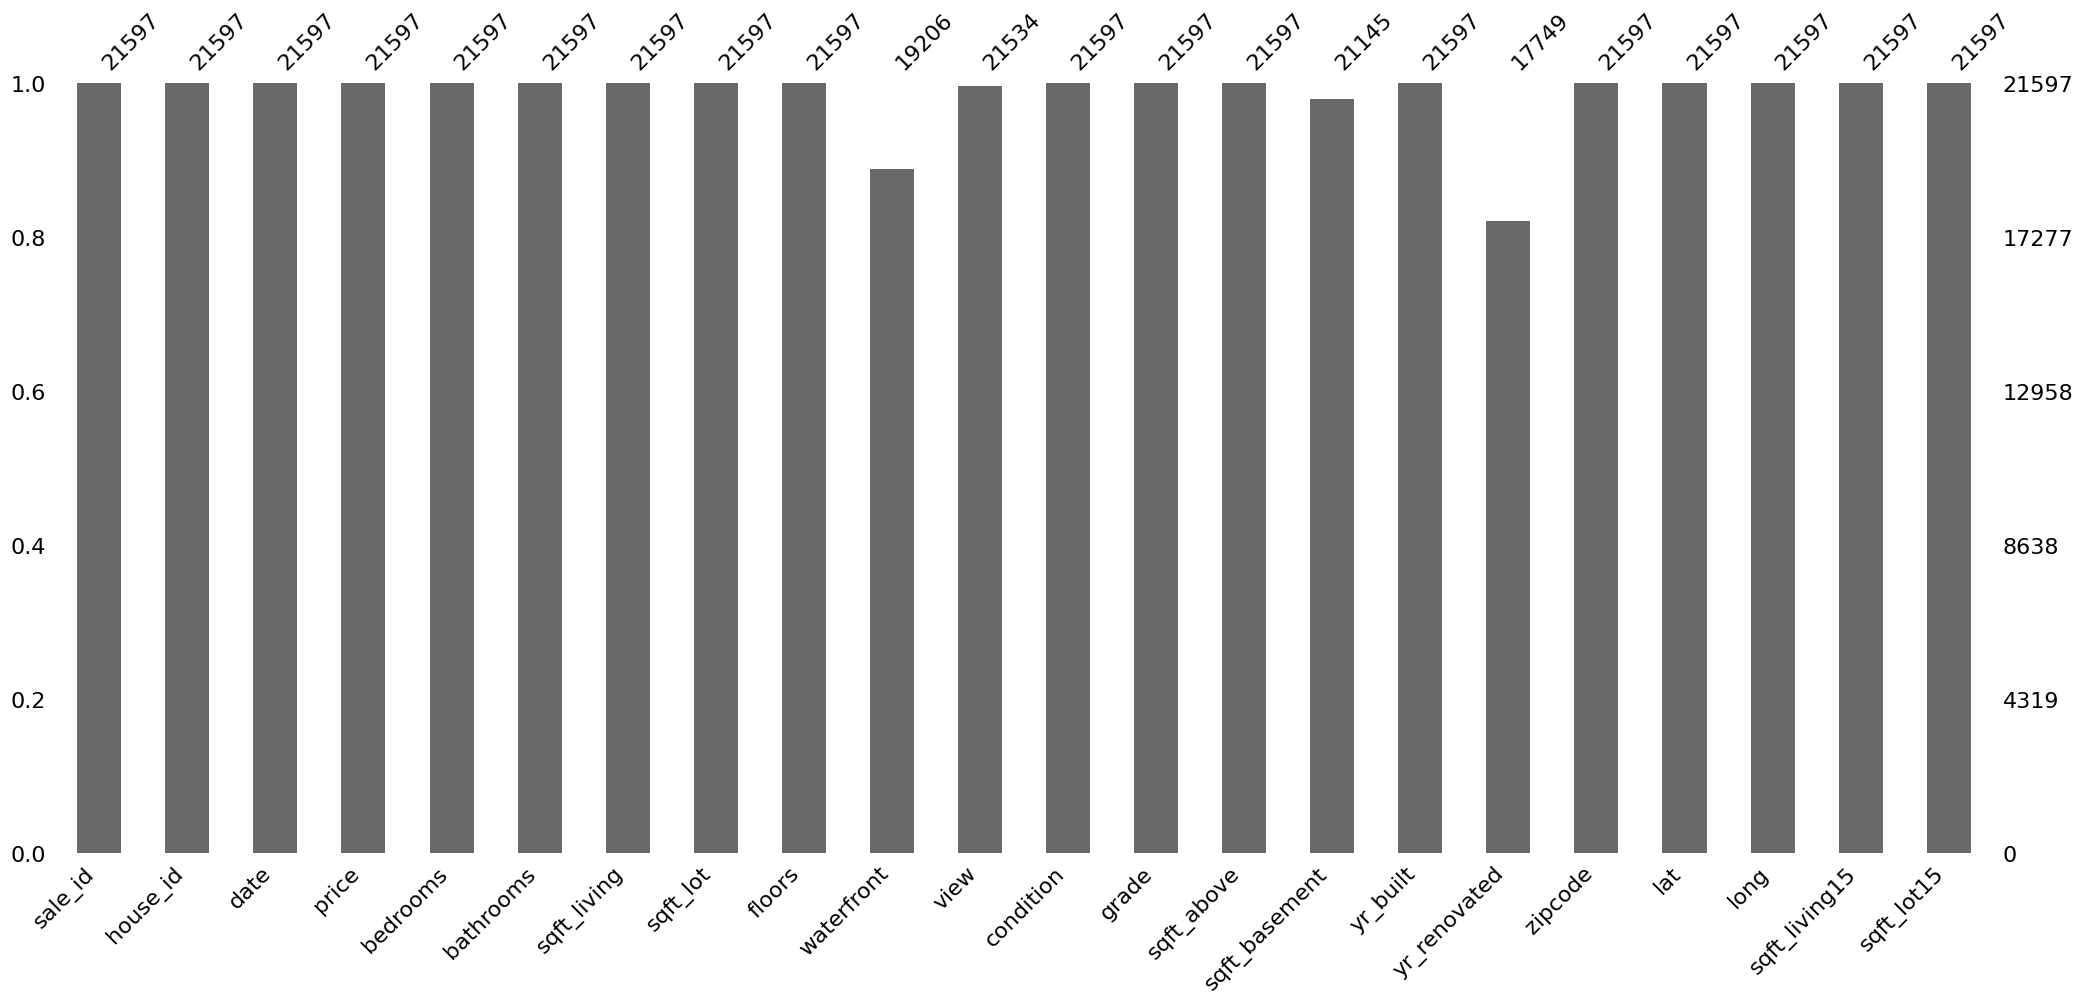

In [ ]:
display(df.isna().sum()[df.isna().sum() > 0])

msno.bar(df)
plt.show()

## 5 · Fehlende Werte auffüllen
* **`sqft_basement`**: In den Daten gilt immer `sqft_living = sqft_above + sqft_basement`. Die Kellerfläche lässt sich also **exakt ausrechnen**.
  Einfach 0 einzusetzen wäre falsch, denn **169 der 452** fehlenden Häuser haben laut Rechnung einen Keller.
* **`waterfront`, `view`**: 0 ist mit großem Abstand der häufigste Wert (Modus), also füllen wir mit 0.
* **`yr_renovated`**: Hier füllen wir ebenfalls mit 0 („nicht renoviert“). Bei ca. 18 % ist das aber nur eine Annahme, deshalb merken wir uns in einer eigenen Spalte, wo der Wert unbekannt war.

In [ ]:
df_imputed = df.copy()

# Modus prüfen: 0 ist mit Abstand der häufigste Wert
display(df_imputed["waterfront"].value_counts(), df_imputed["view"].value_counts())

# Merken, wo das Renovierungsjahr unbekannt war (VOR dem Auffüllen!)
df_imputed["yr_renovated_unbekannt"] = df_imputed["yr_renovated"].isna()

# Kellerfläche = Wohnfläche - oberirdische Fläche
df_imputed["sqft_basement"] = df_imputed["sqft_basement"].fillna(
    df_imputed["sqft_living"] - df_imputed["sqft_above"]
)

df_imputed = df_imputed.fillna({"waterfront": 0, "view": 0, "yr_renovated": 0})

# Kontrolle: Flächenformel stimmt überall, keine fehlenden Werte mehr
print("Formel verletzt:", len(df_imputed.query("sqft_living != sqft_above + sqft_basement")))
print("Fehlende Werte: ", df_imputed.isna().sum().sum())

waterfront
0.00    19060
1.00      146
Name: count, dtype: int64

view
0.00    19422
2.00      957
3.00      508
1.00      330
4.00      317
Name: count, dtype: int64

Formel verletzt: 0
Fehlende Werte:  0


## 6 · Datenfehler korrigieren
* **`bedrooms == 33`**: 1.620 sqft und 1,75 Bäder passen nicht zu 33 Schlafzimmern, gemeint waren 3.
  Die Häuser mit 10–11 Schlafzimmern haben dagegen passende Flächen und bleiben.
* **`yr_renovated`**: Alle Werte über 3000 sind um den Faktor 10 zu groß (z. B. `20150` statt `2015`).

In [ ]:
display(df_imputed.query("bedrooms >= 10")[["price", "bedrooms", "bathrooms", "sqft_living"]])

# Enden alle zu großen Jahreszahlen auf 0? Dann ist "durch 10 teilen" sicher.
print("Werte > 3000, die nicht auf 0 enden:", len(df_imputed.query("yr_renovated > 3000 and yr_renovated % 10 != 0")))

,price,bedrooms,bathrooms,sqft_living
8748,"520,000.00",11.00,3.00,"3,000.00"
13301,"1,150,000.00",10.00,5.25,"4,590.00"
15147,"650,000.00",10.00,2.00,"3,610.00"
15856,"640,000.00",33.00,1.75,"1,620.00"
19239,"660,000.00",10.00,3.00,"2,920.00"


Werte > 3000, die nicht auf 0 enden: 0


In [ ]:
df_imputed["bedrooms"] = df_imputed["bedrooms"].replace(33, 3)
df_imputed.loc[df_imputed["yr_renovated"] > 3000, "yr_renovated"] /= 10

# Ganzzahlen statt Kommazahlen
df_imputed = df_imputed.astype({"bedrooms": int, "yr_renovated": int, "waterfront": int, "view": int})

# Plausibilitätschecks
print("Renovierung vor dem Baujahr:  ", len(df_imputed.query("yr_renovated > 0 and yr_renovated < yr_built")))
print("Renovierung nach dem Verkauf: ", (df_imputed["yr_renovated"] > df_imputed["date"].dt.year).sum())
df_imputed[["bedrooms", "yr_renovated"]].describe()

Renovierung vor dem Baujahr:   0
Renovierung nach dem Verkauf:  6


,bedrooms,yr_renovated
count,"21,597.00","21,597.00"
mean,3.37,68.76
std,0.90,364.04
min,1.00,0.00
25%,3.00,0.00
50%,3.00,0.00
75%,4.00,0.00
max,11.00,"2,015.00"


6 Häuser wurden erst **nach** dem Verkaufsjahr renoviert (vermutlich vom neuen Besitzer, der Datensatz wurde später erstellt).
Das ist kein Tippfehler, deshalb lassen wir die Werte so stehen.

## 7 · sqft → qm umrechnen (1 sqft = 0,092903 qm)

In [ ]:
df_cleaned = df_imputed.copy()

sqft_cols = ["sqft_living", "sqft_lot", "sqft_above", "sqft_basement", "sqft_living15", "sqft_lot15"]
df_cleaned[sqft_cols] = (df_cleaned[sqft_cols] * 0.092903).round(2)
df_cleaned.columns = df_cleaned.columns.str.replace("sqft", "qm")

df_cleaned[["qm_living", "qm_above", "qm_basement", "qm_lot"]].head()

,qm_living,qm_above,qm_basement,qm_lot
0,109.63,109.63,0.00,524.90
1,238.76,201.60,37.16,672.80
2,71.54,71.54,0.00,929.03
3,182.09,97.55,84.54,464.52
4,156.08,156.08,0.00,750.66


## 8 · Keller: Wie viel zählt er zur Wohnfläche?
**Idee:** Kellerfläche nur zu **50 %** zur Wohnfläche zählen (wie oft in Deutschland üblich).

**Prüfung:** Welche Wohnfläche hängt am stärksten mit dem Preis zusammen?
Wir vergleichen Keller zu 100 %, 50 % und 0 %.

In [ ]:
for anteil in [1.0, 0.5, 0.0]:
    flaeche = df_cleaned["qm_above"] + anteil * df_cleaned["qm_basement"]
    print(f"Keller zu {anteil:.0%}: Korrelation mit Preis = {df_cleaned['price'].corr(flaeche):.3f}")

Keller zu 100%: Korrelation mit Preis = 0.702
Keller zu 50%: Korrelation mit Preis = 0.677
Keller zu 0%: Korrelation mit Preis = 0.605


**Entscheidung: Keller zählt zu 100 %, `qm_living` bleibt wie es ist.**
* Mit 100 % ist der Zusammenhang mit dem Preis am stärksten (0,70 gegenüber 0,68 bei 50 %).
  Käufer in King County bezahlen den Keller also fast so wie die oberirdische Fläche.
* In US-Daten zählt `sqft_living` nur **ausgebaute** Keller (*finished basement*), also echten Wohnraum. Die 50-%-Regel kommt aus dem deutschen Recht und passt nicht zu diesen Daten.
* Auch `qm_living15` (Nachbarhäuser) enthält den Keller voll. Mit 50 % wären die beiden Spalten nicht mehr vergleichbar.

Für Analysen, die Häuser nach ihrem Keller unterscheiden wollen, legen wir zusätzlich eine Kategorie an:

In [ ]:
df_cleaned["keller_typ"] = "Nutzbarer Keller (>= 5 qm)"
df_cleaned.loc[df_cleaned["qm_basement"] < 5, "keller_typ"] = "Minikeller (< 5 qm)"
df_cleaned.loc[df_cleaned["qm_basement"] == 0, "keller_typ"] = "Kein Keller (0 qm)"

df_cleaned["keller_typ"].value_counts()

keller_typ
Kein Keller (0 qm)            13110
Nutzbarer Keller (>= 5 qm)     8469
Minikeller (< 5 qm)              18
Name: count, dtype: int64

## 9 · Preis pro qm

In [ ]:
df_cleaned["preis_pro_qm_wohnflaeche"] = (df_cleaned["price"] / df_cleaned["qm_living"]).round(2)
df_cleaned["preis_pro_qm_grundstueck"] = (df_cleaned["price"] / df_cleaned["qm_lot"]).round(2)

df_cleaned[["preis_pro_qm_wohnflaeche", "preis_pro_qm_grundstueck"]].describe()

,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
count,"21,597.00","21,597.00"
mean,"2,843.22",957.87
std,"1,184.03","1,012.45"
min,942.76,1.76
25%,"1,962.18",358.80
50%,"2,633.27",637.89
75%,"3,426.57","1,158.30"
max,"8,719.85","21,739.13"


## 10 · Abschlusscheck & Export

In [ ]:
print(f"Zeilen: {df_cleaned.shape[0]:,}   Spalten: {df_cleaned.shape[1]}")
print(f"Fehlende Werte gesamt: {df_cleaned.isna().sum().sum()}")
df_cleaned.dtypes

Zeilen: 21,597   Spalten: 26
Fehlende Werte gesamt: 0


sale_id                              int64
house_id                             int64
date                        datetime64[us]
price                              float64
bedrooms                             int64
bathrooms                          float64
qm_living                          float64
qm_lot                             float64
floors                             float64
waterfront                           int64
view                                 int64
condition                            int64
grade                                int64
qm_above                           float64
qm_basement                        float64
yr_built                             int64
yr_renovated                         int64
zipcode                              int64
lat                                float64
long                               float64
qm_living15                        float64
qm_lot15                           float64
yr_renovated_unbekannt                bool
keller_typ 

In [ ]:
df_cleaned.to_csv("data/eda_tk_cleaned.csv", index=False)
print("Gespeichert: data/eda_tk_cleaned.csv")

Gespeichert: data/eda_tk_cleaned.csv
